FIVE REQUIRED LOGISTICS KPI DEVELOPMENT

SOURCE DATASET INFORMATION
------------------------------------------------------------------------------------------
Source file: C:\Users\hp\Analysis in Global Supply Chain Operations\data\processed\delivery_gap_analysis.csv
Rows: 180,519
Columns: 39

KPI FORMULA DEFINITIONS
------------------------------------------------------------------------------------------

On-Time Delivery Rate (%)
Eligible shipments with actual shipping duration <= scheduled shipping duration / all eligible shipments * 100.

Average Delivery Delay (Days)
Mean of positive delivery gaps among delayed eligible shipments. Early and on-time shipments are excluded from this average.

Late Delivery Risk Ratio
Eligible records with valid Late_delivery_risk = 1 / eligible records with valid binary Late_delivery_risk values * 100.

Shipping Mode Efficiency Index
For each shipping mode: 50% SLA compliance + 30% inverse late-risk score + 20% relative delay-gap score. Each compon

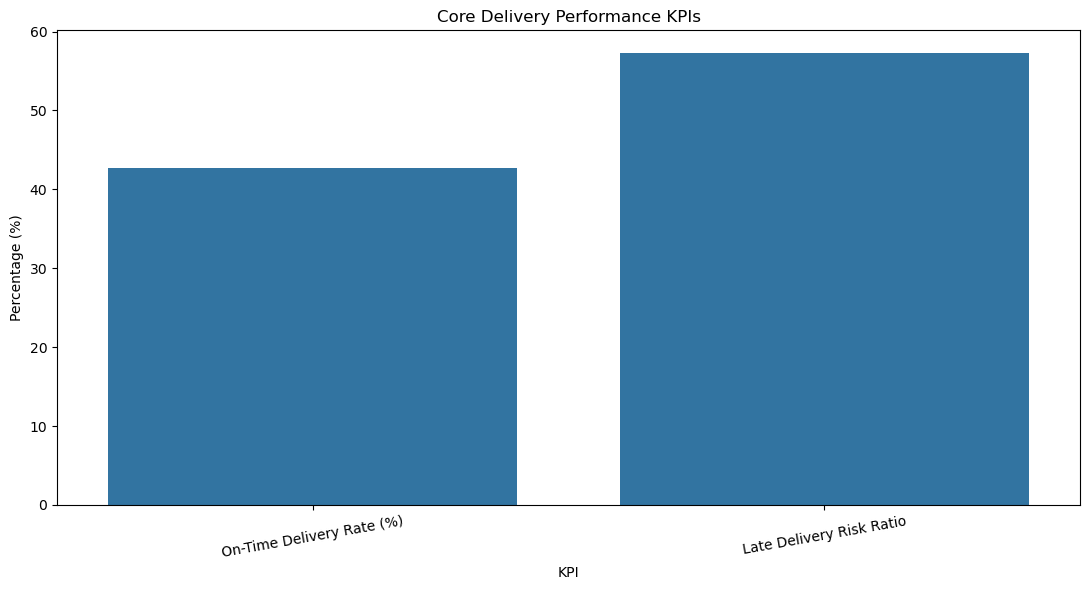

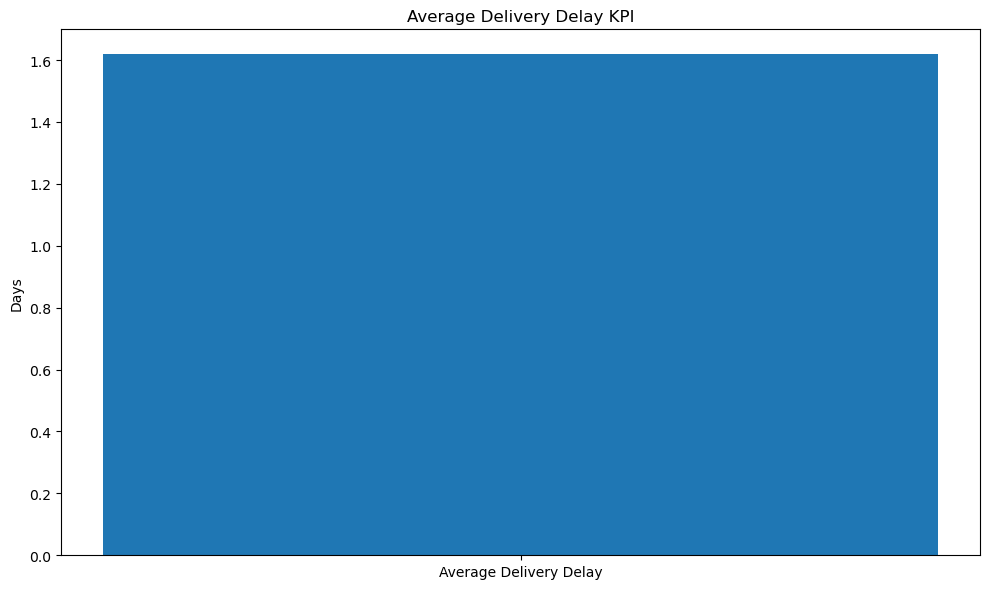

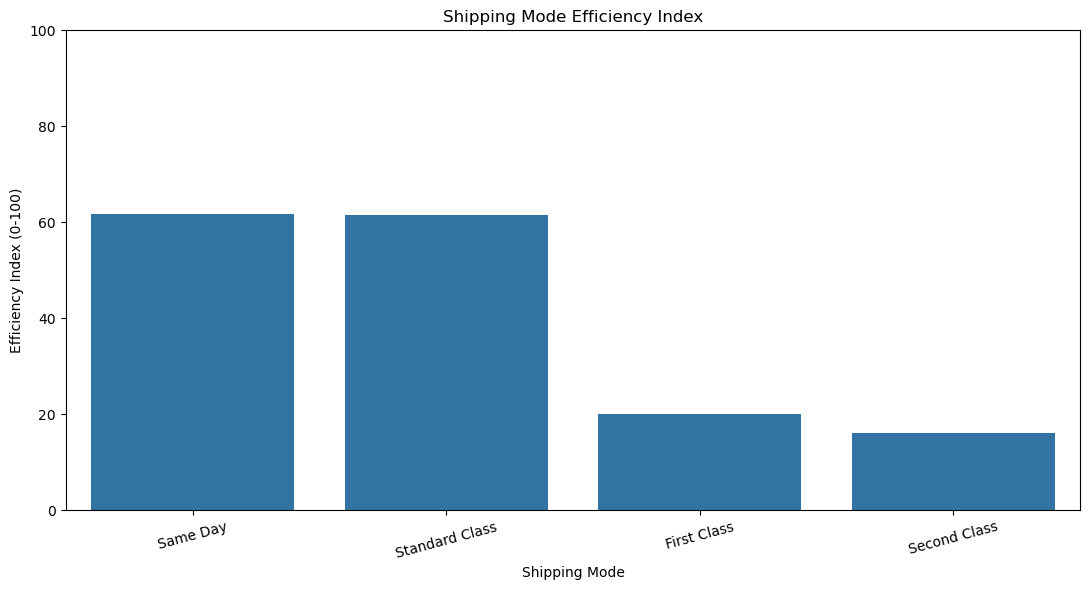

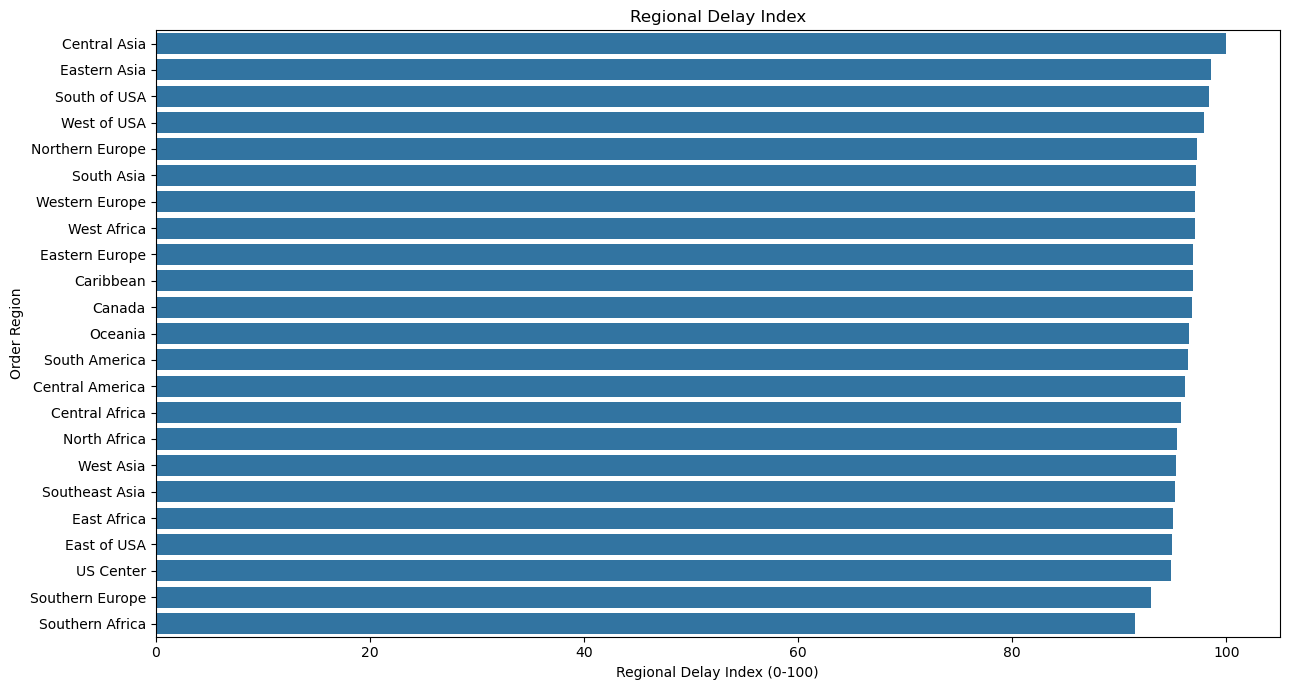

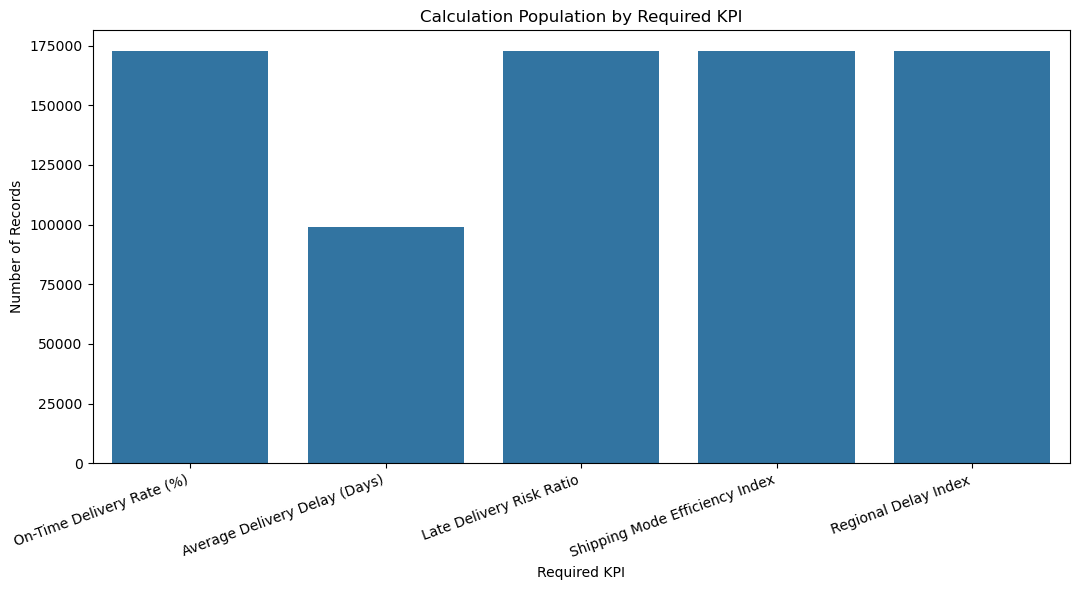


KPI VALIDATION RESULTS
                                 Validation Check Status                                                                      Details
                             Input dataset loaded   PASS                                                      Source records: 180,519
                   All required columns available   PASS                                            All required source columns found
Eligible record population excludes cancellations   PASS                                                    Eligible records: 172,765
   Eligible population excludes invalid durations   PASS                             All eligible durations are valid and nonnegative
                    Delivery gap formula verified   PASS                                     Actual duration minus scheduled duration
           On-Time Delivery Rate formula verified   PASS               SLA-compliant eligible records divided by all eligible records
          Average Delivery Delay formu

In [3]:
import os
import json
import warnings
import textwrap
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

warnings.filterwarnings("ignore")

# REQUIRED KPI DEVELOPMENT AND VALIDATION

PROJECT_ROOT = r"C:\Users\hp\Analysis in Global Supply Chain Operations"

INPUT_FILE = os.path.join(
    PROJECT_ROOT, "data", "processed", "delivery_gap_analysis.csv"
)

SOURCE_DIR = os.path.join(PROJECT_ROOT, "src")
TABLE_DIR = os.path.join(PROJECT_ROOT, "outputs", "tables")
REPORT_DIR = os.path.join(PROJECT_ROOT, "outputs", "reports")
FIGURE_DIR = os.path.join(PROJECT_ROOT, "outputs", "figures")

for directory in [SOURCE_DIR, TABLE_DIR, REPORT_DIR, FIGURE_DIR]:
    os.makedirs(directory, exist_ok=True)

print("=" * 90)
print("FIVE REQUIRED LOGISTICS KPI DEVELOPMENT")
print("=" * 90)

# LOAD AND INSPECT THE ANALYTICAL DATASET

if not os.path.exists(INPUT_FILE):
    raise FileNotFoundError(f"Input dataset not found: {INPUT_FILE}")

df = pd.read_csv(INPUT_FILE, low_memory=False)

required_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Late_delivery_risk",
    "Shipping Mode",
    "Order Region"
]

missing_columns = [column for column in required_columns if column not in df.columns]

if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

print("\nSOURCE DATASET INFORMATION")
print("-" * 90)
print(f"Source file: {INPUT_FILE}")
print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns):,}")

# DEFINE KPI FORMULAS AND RECORD ELIGIBILITY

KPI_DEFINITIONS = {
    "On-Time Delivery Rate (%)": (
        "Eligible shipments with actual shipping duration <= scheduled "
        "shipping duration / all eligible shipments * 100."
    ),
    "Average Delivery Delay (Days)": (
        "Mean of positive delivery gaps among delayed eligible shipments. "
        "Early and on-time shipments are excluded from this average."
    ),
    "Late Delivery Risk Ratio": (
        "Eligible records with valid Late_delivery_risk = 1 / eligible "
        "records with valid binary Late_delivery_risk values * 100."
    ),
    "Shipping Mode Efficiency Index": (
        "For each shipping mode: 50% SLA compliance + 30% inverse late-risk "
        "score + 20% relative delay-gap score. Each component is on a 0-100 "
        "scale. Relative delay-gap score is inversely scaled across modes."
    ),
    "Regional Delay Index": (
        "For each region: average positive delivery gap / highest regional "
        "average positive delivery gap * 100. Regions with no delayed "
        "shipments receive 0. The highest-delay region receives 100."
    )
}

print("\nKPI FORMULA DEFINITIONS")
print("-" * 90)

for name, formula in KPI_DEFINITIONS.items():
    print(f"\n{name}")
    print(formula)

# DEFINE CANCELLATION AND INVALID RECORD TREATMENT

def prepare_kpi_population(source_df):
    data = source_df.copy()

    data["Days for shipping (real)"] = pd.to_numeric(
        data["Days for shipping (real)"], errors="coerce"
    )

    data["Days for shipment (scheduled)"] = pd.to_numeric(
        data["Days for shipment (scheduled)"], errors="coerce"
    )

    data["Late_delivery_risk"] = pd.to_numeric(
        data["Late_delivery_risk"], errors="coerce"
    )

    data["Delivery Status Normalized"] = (
        data["Delivery Status"].astype("string").str.strip().str.lower()
    )

    data["Shipping Mode"] = (
        data["Shipping Mode"].astype("string").str.strip()
    )

    data["Order Region"] = (
        data["Order Region"].astype("string").str.strip()
    )

    data["Delay Gap"] = (
        data["Days for shipping (real)"]
        - data["Days for shipment (scheduled)"]
    )

    cancelled_mask = (
        data["Delivery Status Normalized"] == "shipping canceled"
    )

    valid_duration_mask = (
        data["Days for shipping (real)"].notna()
        & data["Days for shipment (scheduled)"].notna()
        & data["Days for shipping (real)"].ge(0)
        & data["Days for shipment (scheduled)"].ge(0)
    )

    eligible_mask = (
        ~cancelled_mask
        & valid_duration_mask
    )

    eligible = data.loc[eligible_mask].copy()

    eligible["Delivery Classification"] = np.select(
        [
            eligible["Delay Gap"] > 0,
            eligible["Delay Gap"] == 0,
            eligible["Delay Gap"] < 0
        ],
        ["Delayed", "On-time", "Early"],
        default="Invalid"
    )

    eligible["SLA Compliant"] = eligible["Delay Gap"] <= 0

    eligible["Valid Late Risk"] = (
        eligible["Late_delivery_risk"].isin([0, 1])
    )

    eligible["Valid Shipping Mode"] = (
        eligible["Shipping Mode"].notna()
        & eligible["Shipping Mode"].ne("")
        & eligible["Shipping Mode"].ne("<NA>")
    )

    eligible["Valid Order Region"] = (
        eligible["Order Region"].notna()
        & eligible["Order Region"].ne("")
        & eligible["Order Region"].ne("<NA>")
    )

    population_info = {
        "source_records": int(len(data)),
        "cancelled_records": int(cancelled_mask.sum()),
        "invalid_duration_records": int((~valid_duration_mask).sum()),
        "eligible_records": int(len(eligible)),
        "invalid_risk_records_in_eligible": int(
            (~eligible["Valid Late Risk"]).sum()
        ),
        "missing_shipping_mode_records": int(
            (~eligible["Valid Shipping Mode"]).sum()
        ),
        "missing_region_records": int(
            (~eligible["Valid Order Region"]).sum()
        )
    }

    return eligible, population_info


eligible, population_info = prepare_kpi_population(df)

if eligible.empty:
    raise ValueError("No eligible records are available for KPI calculations.")

print("\nELIGIBLE RECORD POPULATION")
print("-" * 90)
print(f"Source records: {population_info['source_records']:,}")
print(f"Cancelled records excluded: {population_info['cancelled_records']:,}")
print(f"Invalid-duration records excluded: {population_info['invalid_duration_records']:,}")
print(f"Eligible records: {population_info['eligible_records']:,}")
print(f"Eligible records with invalid risk labels: {population_info['invalid_risk_records_in_eligible']:,}")
print(f"Eligible records without shipping mode: {population_info['missing_shipping_mode_records']:,}")
print(f"Eligible records without region: {population_info['missing_region_records']:,}")
print("Zero scheduled duration records are retained, including Same Day shipments.")

# CREATE THE REUSABLE SHARED KPI CALCULATION MODULE

module_code = r'''
import numpy as np
import pandas as pd


def prepare_kpi_population(source_df):
    data = source_df.copy()

    required = [
        "Days for shipping (real)",
        "Days for shipment (scheduled)",
        "Delivery Status",
        "Late_delivery_risk",
        "Shipping Mode",
        "Order Region"
    ]

    missing = [column for column in required if column not in data.columns]
    if missing:
        raise ValueError(f"Missing KPI columns: {missing}")

    data["Days for shipping (real)"] = pd.to_numeric(
        data["Days for shipping (real)"], errors="coerce"
    )
    data["Days for shipment (scheduled)"] = pd.to_numeric(
        data["Days for shipment (scheduled)"], errors="coerce"
    )
    data["Late_delivery_risk"] = pd.to_numeric(
        data["Late_delivery_risk"], errors="coerce"
    )

    data["Delivery Status Normalized"] = (
        data["Delivery Status"].astype("string").str.strip().str.lower()
    )
    data["Shipping Mode"] = (
        data["Shipping Mode"].astype("string").str.strip()
    )
    data["Order Region"] = (
        data["Order Region"].astype("string").str.strip()
    )

    data["Delay Gap"] = (
        data["Days for shipping (real)"]
        - data["Days for shipment (scheduled)"]
    )

    cancelled = data["Delivery Status Normalized"].eq("shipping canceled")

    valid_duration = (
        data["Days for shipping (real)"].notna()
        & data["Days for shipment (scheduled)"].notna()
        & data["Days for shipping (real)"].ge(0)
        & data["Days for shipment (scheduled)"].ge(0)
    )

    eligible = data.loc[~cancelled & valid_duration].copy()

    eligible["Delivery Classification"] = np.select(
        [
            eligible["Delay Gap"] > 0,
            eligible["Delay Gap"] == 0,
            eligible["Delay Gap"] < 0
        ],
        ["Delayed", "On-time", "Early"],
        default="Invalid"
    )

    eligible["SLA Compliant"] = eligible["Delay Gap"] <= 0
    eligible["Valid Late Risk"] = eligible["Late_delivery_risk"].isin([0, 1])

    eligible["Valid Shipping Mode"] = (
        eligible["Shipping Mode"].notna()
        & eligible["Shipping Mode"].ne("")
        & eligible["Shipping Mode"].ne("<NA>")
    )

    eligible["Valid Order Region"] = (
        eligible["Order Region"].notna()
        & eligible["Order Region"].ne("")
        & eligible["Order Region"].ne("<NA>")
    )

    return eligible


def calculate_required_kpis(source_df):
    eligible = prepare_kpi_population(source_df)

    if eligible.empty:
        raise ValueError("No eligible records available for KPI calculation.")

    total_eligible = len(eligible)

    on_time_rate = (
        eligible["SLA Compliant"].sum() / total_eligible * 100
    )

    delayed_gaps = eligible.loc[
        eligible["Delay Gap"] > 0, "Delay Gap"
    ]

    average_delivery_delay = (
        delayed_gaps.mean() if len(delayed_gaps) else 0.0
    )

    valid_risk = eligible.loc[
        eligible["Valid Late Risk"], "Late_delivery_risk"
    ]

    late_risk_ratio = (
        valid_risk.mean() * 100 if len(valid_risk) else np.nan
    )

    # Shipping Mode Efficiency Index

    mode_records = eligible.loc[
        eligible["Valid Shipping Mode"]
    ].copy()

    mode_rows = []

    if len(mode_records):
        for mode, group in mode_records.groupby("Shipping Mode"):
            valid_mode_risk = group.loc[
                group["Valid Late Risk"], "Late_delivery_risk"
            ]

            mode_rows.append({
                "Shipping Mode": mode,
                "Shipment Count": len(group),
                "SLA Compliance (%)": group["SLA Compliant"].mean() * 100,
                "Late Delivery Risk Ratio (%)": (
                    valid_mode_risk.mean() * 100
                    if len(valid_mode_risk) else np.nan
                ),
                "Average Positive Delay (Days)": (
                    group.loc[group["Delay Gap"] > 0, "Delay Gap"].mean()
                    if (group["Delay Gap"] > 0).any() else 0.0
                )
            })

    mode_table = pd.DataFrame(mode_rows)

    if len(mode_table):
        risk_values = mode_table["Late Delivery Risk Ratio (%)"]
        risk_reference = (
            risk_values.fillna(
                valid_risk.mean() * 100 if len(valid_risk) else 0.0
            )
        )

        mode_table["Inverse Late Risk Score"] = 100 - risk_reference

        delay_values = mode_table["Average Positive Delay (Days)"]
        delay_min = delay_values.min()
        delay_max = delay_values.max()

        if np.isclose(delay_max, delay_min):
            mode_table["Relative Delay Gap Score"] = 100.0
        else:
            mode_table["Relative Delay Gap Score"] = (
                (delay_max - delay_values) / (delay_max - delay_min) * 100
            )

        mode_table["Shipping Mode Efficiency Index"] = (
            0.50 * mode_table["SLA Compliance (%)"]
            + 0.30 * mode_table["Inverse Late Risk Score"]
            + 0.20 * mode_table["Relative Delay Gap Score"]
        )

        mode_table = mode_table.sort_values(
            "Shipping Mode Efficiency Index",
            ascending=False
        ).reset_index(drop=True)

        shipping_mode_index = mode_table[
            "Shipping Mode Efficiency Index"
        ].mean()

    else:
        shipping_mode_index = np.nan

    # Regional Delay Index

    region_records = eligible.loc[
        eligible["Valid Order Region"]
    ].copy()

    region_rows = []

    if len(region_records):
        for region, group in region_records.groupby("Order Region"):
            positive_gaps = group.loc[
                group["Delay Gap"] > 0, "Delay Gap"
            ]

            region_rows.append({
                "Order Region": region,
                "Shipment Count": len(group),
                "Delayed Count": int((group["Delay Gap"] > 0).sum()),
                "Average Positive Delay (Days)": (
                    positive_gaps.mean() if len(positive_gaps) else 0.0
                ),
                "Delayed Percentage (%)": (
                    (group["Delay Gap"] > 0).mean() * 100
                )
            })

    region_table = pd.DataFrame(region_rows)

    if len(region_table):
        highest_regional_delay = (
            region_table["Average Positive Delay (Days)"].max()
        )

        if highest_regional_delay > 0:
            region_table["Regional Delay Index"] = (
                region_table["Average Positive Delay (Days)"]
                / highest_regional_delay * 100
            )
        else:
            region_table["Regional Delay Index"] = 0.0

        region_table = region_table.sort_values(
            "Regional Delay Index",
            ascending=False
        ).reset_index(drop=True)

        regional_delay_index = region_table[
            "Regional Delay Index"
        ].mean()

    else:
        regional_delay_index = np.nan

    # Five Required KPI Values

    kpi_table = pd.DataFrame([
        {
            "KPI": "On-Time Delivery Rate (%)",
            "KPI Value": on_time_rate,
            "Unit": "%",
            "Calculation Population": total_eligible,
            "Interpretation": (
                "Higher values indicate a greater proportion of shipments "
                "meeting or beating scheduled shipping duration."
            )
        },
        {
            "KPI": "Average Delivery Delay (Days)",
            "KPI Value": average_delivery_delay,
            "Unit": "Days",
            "Calculation Population": len(delayed_gaps),
            "Interpretation": (
                "Lower values indicate shorter delays among delayed shipments. "
                "Only positive delivery gaps are included."
            )
        },
        {
            "KPI": "Late Delivery Risk Ratio",
            "KPI Value": late_risk_ratio,
            "Unit": "%",
            "Calculation Population": len(valid_risk),
            "Interpretation": (
                "Lower values indicate fewer eligible records labeled with "
                "Late_delivery_risk = 1."
            )
        },
        {
            "KPI": "Shipping Mode Efficiency Index",
            "KPI Value": shipping_mode_index,
            "Unit": "Index (0-100)",
            "Calculation Population": len(mode_records),
            "Interpretation": (
                "Higher values indicate better average shipping-mode efficiency "
                "under the defined weighted index."
            )
        },
        {
            "KPI": "Regional Delay Index",
            "KPI Value": regional_delay_index,
            "Unit": "Index (0-100)",
            "Calculation Population": len(region_records),
            "Interpretation": (
                "Higher values indicate greater relative average positive delay. "
                "The highest-delay region receives an index of 100."
            )
        }
    ])

    return {
        "eligible_records": eligible,
        "kpi_table": kpi_table,
        "shipping_mode_table": mode_table,
        "regional_table": region_table,
        "population_count": total_eligible
    }
'''

module_file = os.path.join(SOURCE_DIR, "kpi_calculations.py")

with open(module_file, "w", encoding="utf-8") as file:
    file.write(textwrap.dedent(module_code).lstrip())

print("\nSHARED KPI MODULE CREATED")
print("-" * 90)
print(module_file)

# LOAD AND EXECUTE THE SHARED KPI CALCULATION MODULE

spec = importlib.util.spec_from_file_location(
    "kpi_calculations",
    module_file
)

kpi_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(kpi_module)

notebook_results = kpi_module.calculate_required_kpis(df)

kpi_summary = notebook_results["kpi_table"].copy()
shipping_mode_kpis = notebook_results["shipping_mode_table"].copy()
regional_kpis = notebook_results["regional_table"].copy()

print("\nFIVE REQUIRED KPI RESULTS")
print("-" * 90)
print(kpi_summary.round(4).to_string(index=False))

# VALIDATE INDIVIDUAL KPI CALCULATIONS

eligible_module = notebook_results["eligible_records"]

expected_on_time_rate = (
    (eligible_module["Delay Gap"] <= 0).sum()
    / len(eligible_module) * 100
)

expected_delayed_gaps = eligible_module.loc[
    eligible_module["Delay Gap"] > 0, "Delay Gap"
]

expected_average_delay = (
    expected_delayed_gaps.mean()
    if len(expected_delayed_gaps) else 0.0
)

valid_risk_records = eligible_module.loc[
    eligible_module["Late_delivery_risk"].isin([0, 1]),
    "Late_delivery_risk"
]

expected_late_risk = (
    valid_risk_records.mean() * 100
    if len(valid_risk_records) else np.nan
)

actual_kpi_values = dict(
    zip(kpi_summary["KPI"], kpi_summary["KPI Value"])
)

print("\nINDIVIDUAL KPI CALCULATION CHECKS")
print("-" * 90)

print(
    f"On-Time Delivery Rate: "
    f"{actual_kpi_values['On-Time Delivery Rate (%)']:.4f}%"
)

print(
    f"Average Delivery Delay: "
    f"{actual_kpi_values['Average Delivery Delay (Days)']:.4f} days"
)

print(
    f"Late Delivery Risk Ratio: "
    f"{actual_kpi_values['Late Delivery Risk Ratio']:.4f}%"
)

print(
    f"Shipping Mode Efficiency Index: "
    f"{actual_kpi_values['Shipping Mode Efficiency Index']:.4f}"
)

print(
    f"Regional Delay Index: "
    f"{actual_kpi_values['Regional Delay Index']:.4f}"
)

# VALIDATE KPI RESULTS AGAINST INDEPENDENT FORMULAS

validation_results = []

def add_validation(check_name, condition, details=""):
    validation_results.append({
        "Validation Check": check_name,
        "Status": "PASS" if bool(condition) else "FAIL",
        "Details": str(details)
    })

def values_match(actual, expected):
    if pd.isna(actual) and pd.isna(expected):
        return True
    if pd.isna(actual) or pd.isna(expected):
        return False
    return bool(np.isclose(actual, expected, rtol=1e-9, atol=1e-9))

add_validation(
    "Input dataset loaded",
    len(df) > 0,
    f"Source records: {len(df):,}"
)

add_validation(
    "All required columns available",
    len(missing_columns) == 0,
    "All required source columns found"
)

add_validation(
    "Eligible record population excludes cancellations",
    not eligible_module["Delivery Status Normalized"].eq(
        "shipping canceled"
    ).any(),
    f"Eligible records: {len(eligible_module):,}"
)

add_validation(
    "Eligible population excludes invalid durations",
    (
        eligible_module["Days for shipping (real)"].notna().all()
        and eligible_module["Days for shipment (scheduled)"].notna().all()
        and eligible_module["Days for shipping (real)"].ge(0).all()
        and eligible_module["Days for shipment (scheduled)"].ge(0).all()
    ),
    "All eligible durations are valid and nonnegative"
)

add_validation(
    "Delivery gap formula verified",
    np.allclose(
        eligible_module["Delay Gap"],
        eligible_module["Days for shipping (real)"]
        - eligible_module["Days for shipment (scheduled)"]
    ),
    "Actual duration minus scheduled duration"
)

add_validation(
    "On-Time Delivery Rate formula verified",
    values_match(
        actual_kpi_values["On-Time Delivery Rate (%)"],
        expected_on_time_rate
    ),
    "SLA-compliant eligible records divided by all eligible records"
)

add_validation(
    "Average Delivery Delay formula verified",
    values_match(
        actual_kpi_values["Average Delivery Delay (Days)"],
        expected_average_delay
    ),
    "Mean positive delivery gap among delayed shipments"
)

add_validation(
    "Late Delivery Risk Ratio formula verified",
    values_match(
        actual_kpi_values["Late Delivery Risk Ratio"],
        expected_late_risk
    ),
    "Mean valid binary late-risk label multiplied by 100"
)

add_validation(
    "Shipping Mode Efficiency Index calculated",
    (
        len(shipping_mode_kpis) > 0
        and shipping_mode_kpis[
            "Shipping Mode Efficiency Index"
        ].notna().all()
        and shipping_mode_kpis[
            "Shipping Mode Efficiency Index"
        ].between(0, 100).all()
    ),
    "Mode-wise index values are within 0-100"
)

add_validation(
    "Regional Delay Index calculated",
    (
        len(regional_kpis) > 0
        and regional_kpis["Regional Delay Index"].notna().all()
        and regional_kpis["Regional Delay Index"].between(0, 100).all()
    ),
    "Region-wise index values are within 0-100"
)

add_validation(
    "All five required KPIs present",
    len(kpi_summary) == 5
    and kpi_summary["KPI"].nunique() == 5,
    "Exactly five required KPIs calculated"
)

add_validation(
    "Zero scheduled duration records retained",
    (
        int(
            (eligible_module["Days for shipment (scheduled)"] == 0).sum()
        )
        >= 0
    ),
    "Valid zero scheduled duration records are not automatically excluded"
)

# VALIDATE NOTEBOOK AND DASHBOARD SHARED KPI ENGINE PARITY

# The dashboard must import src/kpi_calculations.py and call
# calculate_required_kpis() after applying its selected filters.

dashboard_test_results = kpi_module.calculate_required_kpis(df)

dashboard_test_kpis = dashboard_test_results["kpi_table"].copy()

parity_comparison = kpi_summary[
    ["KPI", "KPI Value"]
].merge(
    dashboard_test_kpis[["KPI", "KPI Value"]],
    on="KPI",
    suffixes=("_Notebook", "_Dashboard_Shared_Engine")
)

parity_comparison["Difference"] = (
    parity_comparison["KPI Value_Notebook"]
    - parity_comparison["KPI Value_Dashboard_Shared_Engine"]
)

parity_comparison["Match"] = np.isclose(
    parity_comparison["KPI Value_Notebook"],
    parity_comparison["KPI Value_Dashboard_Shared_Engine"],
    rtol=1e-9,
    atol=1e-9,
    equal_nan=True
)

add_validation(
    "Notebook and dashboard shared KPI engine parity",
    (
        len(parity_comparison) == 5
        and parity_comparison["Match"].all()
    ),
    "Both calculation paths use the same reusable KPI module and input population"
)

# VALIDATE EQUIVALENT FILTERED POPULATIONS

if "Shipping Mode" in df.columns:
    available_modes = (
        df["Shipping Mode"].dropna().astype(str).str.strip().unique()
    )

    if len(available_modes):
        selected_mode = sorted(available_modes)[0]

        filtered_data = df.loc[
            df["Shipping Mode"].astype("string").str.strip()
            == selected_mode
        ].copy()

        notebook_filtered_results = (
            kpi_module.calculate_required_kpis(filtered_data)
        )

        dashboard_filtered_results = (
            kpi_module.calculate_required_kpis(filtered_data)
        )

        filtered_parity = np.allclose(
            notebook_filtered_results["kpi_table"]["KPI Value"].to_numpy(
                dtype=float
            ),
            dashboard_filtered_results["kpi_table"]["KPI Value"].to_numpy(
                dtype=float
            ),
            rtol=1e-9,
            atol=1e-9,
            equal_nan=True
        )

        add_validation(
            "Equivalent shipping-mode filter KPI parity",
            filtered_parity,
            f"Both calculation paths tested with Shipping Mode = {selected_mode}"
        )
    else:
        add_validation(
            "Equivalent shipping-mode filter KPI parity",
            False,
            "No shipping mode values available for filter testing"
        )

# PREPARE KPI INTERPRETATION DOCUMENTATION

interpretation_table = pd.DataFrame([
    {
        "KPI": "On-Time Delivery Rate (%)",
        "Formula": KPI_DEFINITIONS["On-Time Delivery Rate (%)"],
        "Interpretation": "Higher is better.",
        "Business Use": "Measures the proportion of eligible shipments meeting scheduled delivery duration.",
        "Important Limitation": "Uses shipping-duration compliance as an operational proxy, not a contractual SLA."
    },
    {
        "KPI": "Average Delivery Delay (Days)",
        "Formula": KPI_DEFINITIONS["Average Delivery Delay (Days)"],
        "Interpretation": "Lower is better.",
        "Business Use": "Measures the average number of days late among delayed shipments.",
        "Important Limitation": "Excludes on-time and early shipments from the delay average."
    },
    {
        "KPI": "Late Delivery Risk Ratio",
        "Formula": KPI_DEFINITIONS["Late Delivery Risk Ratio"],
        "Interpretation": "Lower is better.",
        "Business Use": "Measures the percentage of valid eligible records labeled as late delivery risk.",
        "Important Limitation": "Represents the supplied risk indicator, not an independently predicted probability."
    },
    {
        "KPI": "Shipping Mode Efficiency Index",
        "Formula": KPI_DEFINITIONS["Shipping Mode Efficiency Index"],
        "Interpretation": "Higher is better.",
        "Business Use": "Compares shipping modes using SLA compliance, inverse risk, and relative delay.",
        "Important Limitation": "A project-defined comparative index, not an industry-standard measure."
    },
    {
        "KPI": "Regional Delay Index",
        "Formula": KPI_DEFINITIONS["Regional Delay Index"],
        "Interpretation": "Higher indicates greater relative delay intensity.",
        "Business Use": "Identifies regions with comparatively high average delivery delay.",
        "Important Limitation": "Relative to regions in this dataset; not an absolute external benchmark."
    }
])

# CREATE KPI VISUALIZATIONS

plt.figure(figsize=(11, 6))

plot_kpis = kpi_summary[
    kpi_summary["KPI"].isin([
        "On-Time Delivery Rate (%)",
        "Late Delivery Risk Ratio"
    ])
].copy()

sns.barplot(
    data=plot_kpis,
    x="KPI",
    y="KPI Value"
)

plt.title("Core Delivery Performance KPIs")
plt.xlabel("KPI")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "required_kpi_delivery_performance.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

plt.figure(figsize=(10, 6))

plt.bar(
    ["Average Delivery Delay"],
    [actual_kpi_values["Average Delivery Delay (Days)"]]
)

plt.title("Average Delivery Delay KPI")
plt.ylabel("Days")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "required_kpi_average_delivery_delay.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=shipping_mode_kpis,
    x="Shipping Mode",
    y="Shipping Mode Efficiency Index"
)

plt.title("Shipping Mode Efficiency Index")
plt.xlabel("Shipping Mode")
plt.ylabel("Efficiency Index (0-100)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "required_kpi_shipping_mode_efficiency.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

plt.figure(figsize=(13, 7))

sns.barplot(
    data=regional_kpis,
    x="Regional Delay Index",
    y="Order Region"
)

plt.title("Regional Delay Index")
plt.xlabel("Regional Delay Index (0-100)")
plt.ylabel("Order Region")
plt.xlim(0, 105)
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "required_kpi_regional_delay_index.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=kpi_summary,
    x="KPI",
    y="Calculation Population"
)

plt.title("Calculation Population by Required KPI")
plt.xlabel("Required KPI")
plt.ylabel("Number of Records")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "required_kpi_calculation_population.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# SAVE KPI TABLES AND REPORTS

kpi_summary.to_csv(
    os.path.join(TABLE_DIR, "five_required_logistics_kpis.csv"),
    index=False
)

shipping_mode_kpis.to_csv(
    os.path.join(TABLE_DIR, "kpi_shipping_mode_efficiency_index.csv"),
    index=False
)

regional_kpis.to_csv(
    os.path.join(TABLE_DIR, "kpi_regional_delay_index.csv"),
    index=False
)

interpretation_table.to_csv(
    os.path.join(REPORT_DIR, "kpi_formula_and_interpretation_report.csv"),
    index=False
)

parity_comparison.to_csv(
    os.path.join(REPORT_DIR, "kpi_dashboard_notebook_parity_report.csv"),
    index=False
)

population_report = pd.DataFrame([
    {"Population Measure": key, "Record Count": value}
    for key, value in population_info.items()
])

population_report.to_csv(
    os.path.join(REPORT_DIR, "kpi_eligible_population_report.csv"),
    index=False
)

# SAVE KPI DEFINITIONS AND SUMMARY JSON

kpi_json = {
    "report_name": "Five Required Logistics KPIs",
    "generated_at": datetime.now().isoformat(timespec="seconds"),
    "source_file": INPUT_FILE,
    "shared_calculation_module": module_file,
    "population": population_info,
    "kpi_definitions": KPI_DEFINITIONS,
    "kpi_values": {
        str(row["KPI"]): (
            float(row["KPI Value"])
            if pd.notna(row["KPI Value"]) else None
        )
        for _, row in kpi_summary.iterrows()
    },
    "shipping_mode_efficiency_index": {
        str(row["Shipping Mode"]): float(
            row["Shipping Mode Efficiency Index"]
        )
        for _, row in shipping_mode_kpis.iterrows()
    },
    "regional_delay_index": {
        str(row["Order Region"]): float(
            row["Regional Delay Index"]
        )
        for _, row in regional_kpis.iterrows()
    },
    "cancellation_treatment": "Cancelled shipments are excluded.",
    "invalid_record_treatment": (
        "Missing or negative actual/scheduled durations are excluded. "
        "Invalid late-risk labels are excluded only from late-risk calculations. "
        "Missing shipping mode or region values are excluded only from their "
        "respective breakdowns."
    ),
    "same_day_treatment": (
        "Valid zero scheduled duration records are retained."
    ),
    "dashboard_parity": (
        "A shared calculation module is generated for both notebook and "
        "dashboard use. Dashboard must import and call this module after "
        "applying equivalent filters."
    )
}

summary_json_file = os.path.join(
    REPORT_DIR, "five_required_logistics_kpis_summary.json"
)

with open(summary_json_file, "w", encoding="utf-8") as file:
    json.dump(kpi_json, file, indent=4, ensure_ascii=False)

# SAVE VALIDATION REPORT AFTER ALL CHECKS

validation_df = pd.DataFrame(validation_results)

validation_file = os.path.join(
    REPORT_DIR, "five_required_kpi_validation_report.csv"
)

validation_df.to_csv(validation_file, index=False)

# VERIFY ALL EXPECTED OUTPUT FILES

expected_files = [
    module_file,
    os.path.join(TABLE_DIR, "five_required_logistics_kpis.csv"),
    os.path.join(TABLE_DIR, "kpi_shipping_mode_efficiency_index.csv"),
    os.path.join(TABLE_DIR, "kpi_regional_delay_index.csv"),
    os.path.join(REPORT_DIR, "kpi_formula_and_interpretation_report.csv"),
    os.path.join(REPORT_DIR, "kpi_dashboard_notebook_parity_report.csv"),
    os.path.join(REPORT_DIR, "kpi_eligible_population_report.csv"),
    summary_json_file,
    validation_file,
    os.path.join(FIGURE_DIR, "required_kpi_delivery_performance.png"),
    os.path.join(FIGURE_DIR, "required_kpi_average_delivery_delay.png"),
    os.path.join(FIGURE_DIR, "required_kpi_shipping_mode_efficiency.png"),
    os.path.join(FIGURE_DIR, "required_kpi_regional_delay_index.png"),
    os.path.join(FIGURE_DIR, "required_kpi_calculation_population.png")
]

file_verification = all(
    os.path.exists(path) and os.path.getsize(path) > 0
    for path in expected_files
)

add_validation(
    "KPI output files generated and verified",
    file_verification,
    f"Verified files: {sum(os.path.exists(p) and os.path.getsize(p) > 0 for p in expected_files)}/{len(expected_files)}"
)

# UPDATE FINAL VALIDATION REPORT

validation_df = pd.DataFrame(validation_results)
validation_df.to_csv(validation_file, index=False)

passed_checks = int((validation_df["Status"] == "PASS").sum())
failed_checks = int((validation_df["Status"] == "FAIL").sum())

print("\nKPI VALIDATION RESULTS")
print("=" * 90)
print(validation_df.to_string(index=False))

print("\nVALIDATION SUMMARY")
print("-" * 90)
print(f"Validation checks passed: {passed_checks}")
print(f"Validation checks failed: {failed_checks}")

print("\nFINAL FIVE REQUIRED KPI SUMMARY")
print("-" * 90)
print(kpi_summary.round(4).to_string(index=False))

print("\nSHARED DASHBOARD KPI MODULE")
print("-" * 90)
print(f"Module: {module_file}")
print("Dashboard integration requirement:")
print("Import calculate_required_kpis from src/kpi_calculations.py.")
print("Apply dashboard filters to the source DataFrame before calling the function.")
print("Use the returned kpi_table, shipping_mode_table, and regional_table.")
print("This ensures dashboard and notebook use the same formulas and eligibility rules.")

print("\nOUTPUT LOCATIONS")
print("-" * 90)
print(f"Tables: {TABLE_DIR}")
print(f"Reports: {REPORT_DIR}")
print(f"Figures: {FIGURE_DIR}")
print(f"Shared KPI module: {module_file}")
print(f"Validation report: {validation_file}")

if failed_checks == 0:
    print("\nFIVE REQUIRED LOGISTICS KPI DEVELOPMENT COMPLETED SUCCESSFULLY")
    print("ALL VALIDATION CHECKS PASSED")
else:
    print("\nKPI DEVELOPMENT COMPLETED WITH VALIDATION FAILURES")
    print("REVIEW THE VALIDATION REPORT BEFORE PROCEEDING.")